# Task 17 - Customer Engagement Feature (time-series, thresholds, clustering)

**Goal:** create `is_highly_engaged` and a dynamic `engagement_score` (0-100) by (1) analysing session-activity time series, (2) applying statistical thresholds and (3) clustering customers into engagement levels.

**Input:** newest available dataset in `data/processed/` (Task 16 output preferred)
**Outputs:** `data/processed/womens_clothing_engagement_features.csv`, `reports/task_17_engagement_cluster_profile.csv`, `reports/task_17_engagement_thresholds.csv`, `reports/task_17_analysis_status.csv`

> **Data caveat - please read.** The Women's Clothing dataset has **no session, timestamp or customer-id columns**, so real session time series do not exist here.
> - If your data contains real columns (a user id plus a date/timestamp), set `SESSION_MODE = "real"` and map them below.
> - Otherwise `SESSION_MODE = "simulated"` (default) generates a **seeded synthetic weekly session log** whose intensity is driven by real engagement signals (positive feedback received, review effort, recommendation, sentiment strength) plus noise. All simulated columns are prefixed `sim_`. This demonstrates the full time-series -> threshold -> clustering pipeline, but the result is a *proxy for engagement*, not observed behaviour.
> - `SESSION_MODE = "proxy"` skips time series and clusters on the static signals only.

In [1]:
import re, warnings
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

def find_project_root():
    """Walk up from the notebook folder until a folder containing data/processed is found."""
    start = Path.cwd().resolve()
    for cand in [start, *start.parents]:
        if (cand / "data" / "processed").exists():
            return cand
    return start.parent

ROOT = find_project_root()
PROC = ROOT / "data" / "processed"
REPORTS = ROOT / "reports"
PROC.mkdir(parents=True, exist_ok=True)
REPORTS.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

def _norm(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())

def pick(df, *candidates, required=True):
    """Return the real column name matching any candidate (ignores case, spaces, underscores)."""
    lookup = {_norm(c): c for c in df.columns}
    for cand in candidates:
        if _norm(cand) in lookup:
            return lookup[_norm(cand)]
    if required:
        raise KeyError(f"None of {candidates} found. Columns: {list(df.columns)}")
    return None

def load_first(*paths, require_any=None):
    """Load the first existing CSV (optionally one that has at least one of the required columns)."""
    for p in paths:
        if not Path(p).exists():
            continue
        d = pd.read_csv(p)
        d = d.loc[:, ~d.columns.str.startswith("Unnamed")]
        if require_any and not any(_norm(c) in {_norm(x) for x in d.columns} for c in require_any):
            print(f"Skipped {Path(p).name}: none of {require_any} present")
            continue
        print(f"Loaded: {Path(p).name}  shape={d.shape}")
        return d, Path(p)
    raise FileNotFoundError("No usable file found among: " + ", ".join(str(p) for p in paths))

# Newest cumulative dataset first; each task falls back to an earlier file if a later one does not exist yet.
CHAIN = ["womens_clothing_high_cardinality_encoded.csv", "womens_clothing_engagement_features.csv",
         "womens_clothing_sentiment_features.csv", "womens_clothing_age_segmented.csv",
         "womens_clothing_review_text_features.csv", "womens_clothing_market_basket_features.csv",
         "womens_clothing_product_text_features.csv", "womens_clothing_product_tag_features.csv",
         "womens_clothing_product_segmented.csv", "womens_clothing_final.csv"]

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
RANDOM_STATE = 42

# ---------------- configuration ----------------
SESSION_MODE = "simulated"     # "simulated" | "proxy" | "real"
N_WEEKS = 12
Z_HIGH = 0.5                   # statistical threshold: engagement index z-score above this
K_RANGE = range(3, 6)          # engagement levels tried by K-means
# only used when SESSION_MODE == "real": a long table with one row per session/week
REAL_SESSIONS_FILE = None      # e.g. PROC / "sessions.csv"  with columns below
REAL_USER_COL, REAL_DATE_COL = "customer_id", "session_date"

Project root: D:\OneDrive\Desktop\Brainybeams\Womens_Clothing_ML_Project


## 1. Load data and build static engagement signals

In [2]:
candidates = [PROC / n for n in CHAIN]
candidates += sorted(PROC.glob("*.csv"), reverse=True)
candidates += [ROOT / "data" / "interim" / "womens_clothing_standardized.csv",
               ROOT / "data" / "interim" / "womens_clothing_cleaned.csv",
               ROOT / "data" / "raw" / "womens_clothing.csv"]
df, src = load_first(*candidates)
rating_col = pick(df, "Rating")
rec_col    = pick(df, "Recommended IND", "Recommended", required=False)
pf_col     = pick(df, "Positive Feedback Count", required=False)
text_col   = pick(df, "Review Text", "Review", required=False)
title_col  = pick(df, "Title", required=False)
wc_col     = pick(df, "txt_word_count", required=False)
sent_col   = pick(df, "sentiment_raw", "txt_sent_compound", required=False)

sig = pd.DataFrame(index=df.index)
sig["feedback_received"] = df[pf_col].fillna(0) if pf_col else 0
if wc_col: sig["review_effort"] = df[wc_col].fillna(0)
elif text_col: sig["review_effort"] = df[text_col].astype("string").fillna("").str.split().str.len()
else: sig["review_effort"] = 0
sig["has_title"] = df[title_col].notna().astype(int) if title_col else 0
sig["recommended"] = df[rec_col].fillna(0) if rec_col else 0
sig["opinion_strength"] = df[sent_col].abs().fillna(0) if sent_col else (df[rating_col] - 3).abs() / 2

def zs(s): return (s - s.mean()) / (s.std() + 1e-9)
sig["latent_engagement"] = (0.35 * zs(np.log1p(sig["feedback_received"])) + 0.30 * zs(np.log1p(sig["review_effort"])) +
                            0.10 * zs(sig["has_title"]) + 0.10 * zs(sig["recommended"]) + 0.15 * zs(sig["opinion_strength"]))
sig.describe().T.round(3)

Loaded: womens_clothing_sentiment_features.csv  shape=(1539, 59)


,count,mean,std,min,25%,50%,75%,max
feedback_received,1539.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
review_effort,1539.0,44.750,12.472,18.000,36.000,42.000,50.000,117.000
has_title,1539.0,1.000,0.000,1.000,1.000,1.000,1.000,1.000
recommended,1539.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
opinion_strength,1539.0,0.709,0.162,0.203,0.577,0.684,0.885,0.979
latent_engagement,1539.0,-0.000,0.366,-1.125,-0.260,-0.039,0.232,1.393


## 2. Session activity time series

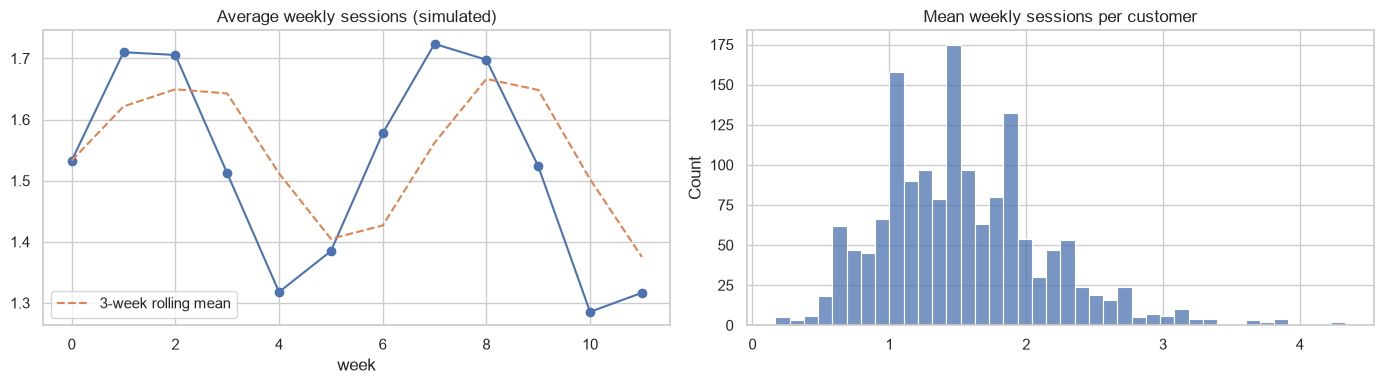

Aggregate lag-1 autocorrelation: 0.547


In [3]:
rng = np.random.default_rng(RANDOM_STATE)
t = np.arange(N_WEEKS)
mode_used = SESSION_MODE

if SESSION_MODE == "simulated":
    base = np.exp(0.6 * sig["latent_engagement"].values + 0.4)          # expected sessions per week
    drift = rng.normal(0, 0.04, len(df))[:, None]                         # individual growth / decay
    season = 1 + 0.15 * np.sin(2 * np.pi * t / N_WEEKS * 2)[None, :]     # shared seasonality
    lam = np.clip(base[:, None] * (1 + drift * t[None, :]) * season, 0.05, None)
    weekly = rng.poisson(lam).astype(float)                              # n_customers x N_WEEKS
elif SESSION_MODE == "real":
    s = pd.read_csv(REAL_SESSIONS_FILE, parse_dates=[REAL_DATE_COL])
    s["week"] = s[REAL_DATE_COL].dt.to_period("W")
    pivot = s.groupby([REAL_USER_COL, "week"]).size().unstack(fill_value=0).iloc[:, -N_WEEKS:]
    key = pick(df, REAL_USER_COL)
    weekly = pivot.reindex(df[key]).fillna(0).values
    N_WEEKS = weekly.shape[1]; t = np.arange(N_WEEKS)
else:
    weekly = None
    print("proxy mode: no time-series features")

if weekly is not None:
    agg = weekly.mean(axis=0)
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    ax[0].plot(t, agg, marker="o"); ax[0].plot(t, pd.Series(agg).rolling(3, min_periods=1).mean(), "--", label="3-week rolling mean")
    ax[0].set_title(f"Average weekly sessions ({mode_used})"); ax[0].set_xlabel("week"); ax[0].legend()
    sns.histplot(weekly.mean(axis=1), bins=40, ax=ax[1], color="#4c72b0"); ax[1].set_title("Mean weekly sessions per customer")
    plt.tight_layout(); plt.show()
    print("Aggregate lag-1 autocorrelation:", round(pd.Series(agg).autocorr(1), 3))

### Time-series features per customer

mean activity, recent activity (last 4 weeks), exponentially weighted average, linear trend slope, volatility, burstiness, share of active weeks and longest inactive streak.

In [4]:
def longest_zero_run(row):
    best = cur = 0
    for v in row:
        cur = cur + 1 if v == 0 else 0
        best = max(best, cur)
    return best

ts = pd.DataFrame(index=df.index)
if weekly is not None:
    tc = t - t.mean()
    ts["sim_mean_sessions"] = weekly.mean(axis=1)
    ts["sim_recent_sessions"] = weekly[:, -4:].mean(axis=1)
    w = 0.3 * (1 - 0.3) ** np.arange(N_WEEKS)[::-1]
    ts["sim_ewma_sessions"] = (weekly * w).sum(axis=1) / w.sum()
    ts["sim_trend_slope"] = (weekly - weekly.mean(axis=1, keepdims=True)) @ tc / (tc ** 2).sum()
    sd = weekly.std(axis=1); mu = weekly.mean(axis=1)
    ts["sim_volatility"] = sd
    ts["sim_burstiness"] = np.where(sd + mu > 0, (sd - mu) / (sd + mu + 1e-9), 0)
    ts["sim_active_week_ratio"] = (weekly > 0).mean(axis=1)
    ts["sim_longest_inactive_streak"] = [longest_zero_run(r) for r in weekly]
    prefix = "sim_" if mode_used == "simulated" else "ts_"
    if prefix == "ts_": ts.columns = [c.replace("sim_", "ts_") for c in ts.columns]
ts.describe().T.round(3) if len(ts.columns) else "no time-series features (proxy mode)"

,count,mean,std,min,25%,50%,75%,max
sim_mean_sessions,1539.0,1.524,0.602,0.167,1.083,1.500,1.833,4.333
sim_recent_sessions,1539.0,1.456,0.878,0.000,0.750,1.250,2.000,5.750
sim_ewma_sessions,1539.0,1.439,0.780,0.015,0.862,1.345,1.904,5.531
sim_trend_slope,1539.0,-0.018,0.113,-0.336,-0.091,-0.021,0.052,0.423
sim_volatility,1539.0,1.164,0.342,0.373,0.913,1.143,1.382,2.812
sim_burstiness,1539.0,-0.113,0.143,-0.621,-0.208,-0.115,-0.021,0.406
sim_active_week_ratio,1539.0,0.752,0.160,0.167,0.667,0.750,0.833,1.000
sim_longest_inactive_streak,1539.0,1.613,1.142,0.000,1.000,1.000,2.000,10.000


## 3. Engagement index and statistical thresholds

{'z_high_threshold': 0.5, 'mean': np.float64(-0.0), 'std': np.float64(1.0), 'index_cutoff_z': np.float64(0.5), 'p75': np.float64(0.657), 'p90': np.float64(1.262), 'recent_activity_median': 1.25}
Statistically high: 29.7%


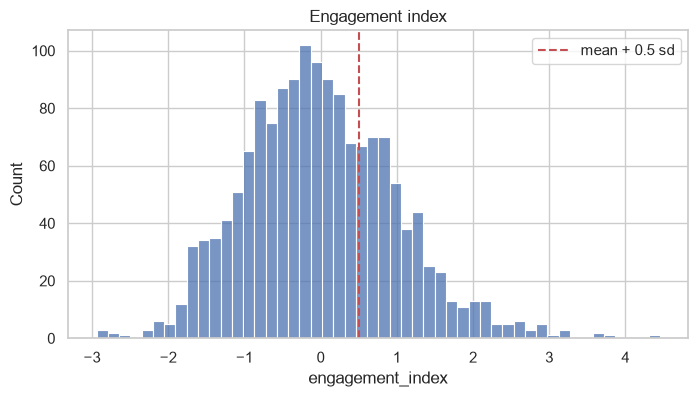

In [5]:
feat = sig[["feedback_received", "review_effort", "has_title", "recommended", "opinion_strength"]].copy()
ts_cols = list(ts.columns)
if ts_cols:
    pre = ts_cols[0].split("_")[0] + "_"
    feat = pd.concat([feat, ts], axis=1)
    index_parts = (0.30 * zs(feat[pre + "ewma_sessions"]) + 0.15 * zs(feat[pre + "mean_sessions"]) + 0.15 * zs(feat[pre + "active_week_ratio"])
                   + 0.10 * zs(feat[pre + "trend_slope"]) - 0.05 * zs(feat[pre + "longest_inactive_streak"])
                   + 0.15 * zs(np.log1p(feat["feedback_received"])) + 0.10 * zs(np.log1p(feat["review_effort"])))
    recent_col = pre + "recent_sessions"
else:
    index_parts = sig["latent_engagement"]; recent_col = None

df["engagement_index"] = zs(index_parts)

mu, sd = df["engagement_index"].mean(), df["engagement_index"].std()
thr = {"z_high_threshold": Z_HIGH, "mean": mu, "std": sd, "index_cutoff_z": mu + Z_HIGH * sd,
       "p75": df["engagement_index"].quantile(0.75), "p90": df["engagement_index"].quantile(0.90)}
stat_high = df["engagement_index"] >= thr["index_cutoff_z"]
if recent_col:                      # must not be fading: recent activity at least the median
    thr["recent_activity_median"] = float(feat[recent_col].median())
    stat_high &= feat[recent_col] >= thr["recent_activity_median"]
df["engagement_stat_high"] = stat_high.astype(int)
print({k: round(v, 3) for k, v in thr.items()}); print("Statistically high:", f"{stat_high.mean():.1%}")

plt.figure(figsize=(8, 4)); sns.histplot(df["engagement_index"], bins=50, color="#4c72b0")
plt.axvline(thr["index_cutoff_z"], color="#c44e52", ls="--", label=f"mean + {Z_HIGH} sd"); plt.legend(); plt.title("Engagement index"); plt.show()

## 4. Cluster customers into engagement levels

In [6]:
cluster_cols = [c for c in feat.columns if c not in ("has_title", "recommended")] + ["engagement_index"]
Xc = StandardScaler().fit_transform(np.log1p(feat[[c for c in cluster_cols if c in feat.columns and feat[c].min() >= 0]]).join(df[["engagement_index"]]))
rows = []
for k in K_RANGE:
    km = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(Xc)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(Xc, km.labels_, sample_size=min(8000, len(Xc)), random_state=RANDOM_STATE)})
kscan = pd.DataFrame(rows); display(kscan.round(4))
best_k = int(kscan.sort_values("silhouette", ascending=False).iloc[0]["k"])
km = KMeans(best_k, n_init=10, random_state=RANDOM_STATE).fit(Xc)
order = df.groupby(km.labels_)["engagement_index"].mean().sort_values().index
names = {2: ["Low", "High"], 3: ["Low", "Medium", "High"], 4: ["Low", "Medium", "High", "Very high"], 5: ["Very low", "Low", "Medium", "High", "Very high"]}[best_k]
rank_map = {c: i for i, c in enumerate(order)}
df["engagement_cluster_id"] = pd.Series(km.labels_, index=df.index).map(rank_map)
df["engagement_level"] = df["engagement_cluster_id"].map(dict(enumerate(names)))
print("k =", best_k); df["engagement_level"].value_counts(normalize=True).reindex(names).round(3)

,k,inertia,silhouette
0,3,6747.8669,0.2393
1,4,6040.6697,0.1882
2,5,5498.0350,0.1945


k = 3


engagement_level
Low       0.257
Medium    0.491
High      0.253
Name: proportion, dtype: float64

## 5. Dynamic engagement score and the high-engagement flag

- `engagement_score` (0-100): percentile rank of the engagement index, blended with the customer's cluster position so that scores respect both the continuum and the segment structure.
- `is_highly_engaged = 1` when the customer passes the **statistical threshold** *and* sits in one of the **top two clusters**.

Highly engaged: 23.8% (367 customers)


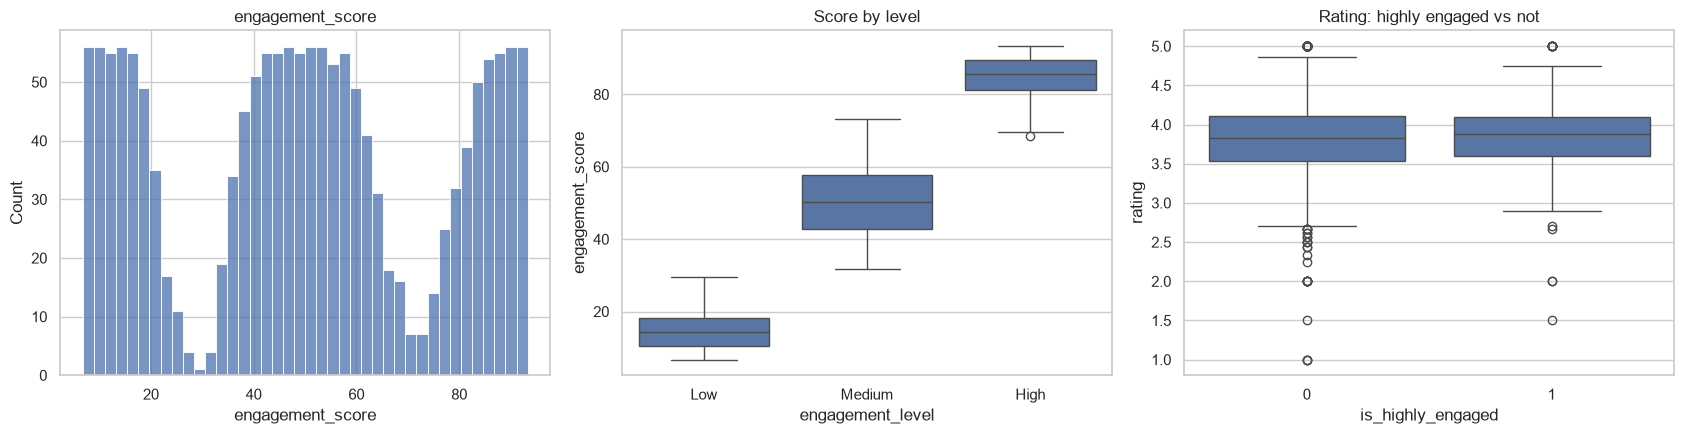

In [7]:
pct = df["engagement_index"].rank(pct=True)
cluster_pos = (df["engagement_cluster_id"] + 0.5) / best_k
df["engagement_score"] = (100 * (0.6 * pct + 0.4 * cluster_pos)).round(2)
top_clusters = [best_k - 1] if best_k <= 3 else [best_k - 2, best_k - 1]
df["is_highly_engaged"] = ((df["engagement_stat_high"] == 1) & df["engagement_cluster_id"].isin(top_clusters)).astype(int)
print(f"Highly engaged: {df['is_highly_engaged'].mean():.1%} ({df['is_highly_engaged'].sum():,} customers)")

# attach time-series features and signals to the dataset
for c in ts.columns: df[c] = ts[c]
df["engagement_data_mode"] = mode_used

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(df["engagement_score"], bins=40, ax=ax[0], color="#4c72b0"); ax[0].set_title("engagement_score")
sns.boxplot(data=df, x="engagement_level", y="engagement_score", order=names, ax=ax[1]); ax[1].set_title("Score by level")
sns.boxplot(data=df, x="is_highly_engaged", y=rating_col, ax=ax[2]); ax[2].set_title("Rating: highly engaged vs not")
plt.tight_layout(); plt.show()

In [8]:
prof_cols = ["engagement_index", "engagement_score", "feedback_received", "review_effort"] + list(ts.columns)
tmp = pd.concat([df[["engagement_level", "engagement_cluster_id", "is_highly_engaged", rating_col]], sig[["feedback_received", "review_effort"]],
                 df[["engagement_index", "engagement_score"] + list(ts.columns)]], axis=1)
profile = tmp.groupby(["engagement_cluster_id", "engagement_level"]).agg(customers=(rating_col, "size"), mean_rating=(rating_col, "mean"),
          highly_engaged_share=("is_highly_engaged", "mean"), **{c: (c, "mean") for c in prof_cols if c in tmp.columns}).reset_index()
profile["share"] = profile["customers"] / profile["customers"].sum()
profile.round(3)

,engagement_cluster_id,engagement_level,customers,mean_rating,highly_engaged_share,engagement_index,engagement_score,feedback_received,review_effort,sim_mean_sessions,sim_recent_sessions,sim_ewma_sessions,sim_trend_slope,sim_volatility,sim_burstiness,sim_active_week_ratio,sim_longest_inactive_streak,share
0,0,Low,395,3.805,0.000,-1.180,14.667,0.0,38.484,0.876,0.550,0.605,-0.077,0.926,0.031,0.560,2.800,0.257
1,1,Medium,755,3.827,0.000,-0.034,50.304,0.0,42.701,1.469,1.397,1.380,-0.021,1.145,-0.129,0.774,1.420,0.491
2,2,High,389,3.834,0.943,1.265,85.159,0.0,55.093,2.289,2.489,2.400,0.047,1.443,-0.227,0.905,0.784,0.253


## 6. Save outputs

In [9]:
out = df.copy()
for c in ["feedback_received", "review_effort"]:           # keep the base signals (useful later) under explicit names
    out["eng_" + c] = sig[c]
out_path = PROC / "womens_clothing_engagement_features.csv"
out.to_csv(out_path, index=False)

profile.to_csv(REPORTS / "task_17_engagement_cluster_profile.csv", index=False)
pd.DataFrame([{"threshold": k, "value": v} for k, v in thr.items()]).to_csv(REPORTS / "task_17_engagement_thresholds.csv", index=False)

base_cols = pd.read_csv(src, nrows=1).columns
new_cols = [c for c in out.columns if c not in base_cols]
status = pd.DataFrame([{
    "task": "Task 17 - Customer Engagement Feature", "status": "completed",
    "run_at": datetime.now().isoformat(timespec="seconds"), "input_file": src.name,
    "session_mode": mode_used, "rows_in": len(df), "rows_out": len(out), "n_weeks": N_WEEKS if weekly is not None else 0,
    "kmeans_k": best_k, "highly_engaged_share": round(df["is_highly_engaged"].mean(), 4),
    "columns_added": len(new_cols), "new_columns": ";".join(new_cols), "output_dataset": out_path.name,
    "note": "simulated sessions - proxy for engagement" if mode_used == "simulated" else ""}])
status.to_csv(REPORTS / "task_17_analysis_status.csv", index=False)
status.T

,0
task,Task 17 - Customer Engagement Feature
status,completed
run_at,2026-11-23T16:51:09
input_file,womens_clothing_sentiment_features.csv
session_mode,simulated
rows_in,1539
rows_out,1539
n_weeks,12
kmeans_k,3
highly_engaged_share,0.2385
